In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("라이브러리 로딩 완료!")

라이브러리 로딩 완료!


In [2]:
import pandas as pd
df = pd.read_csv('data/changwon_temp.csv', encoding='cp949', skiprows=7)
df.columns = df.columns.str.strip()
df['날짜'] = pd.to_datetime(df['날짜'].astype(str).str.strip())
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
print('Duplicate dates:', df['날짜'].duplicated().sum())
print('Missing values:')
print(df.isna().sum())
display(df.head())


Shape: (9788, 5)
Columns: ['날짜', '지점', '평균기온(℃)', '최저기온(℃)', '최고기온(℃)']
Duplicate dates: 0
Missing values:
날짜         0
지점         0
평균기온(℃)    0
최저기온(℃)    1
최고기온(℃)    1
dtype: int64


,날짜,지점,평균기온(℃),최저기온(℃),최고기온(℃)
0,2000-01-01,155,7.5,1.8,11.7
1,2000-01-02,155,8.8,5.2,12.6
2,2000-01-03,155,5.3,1.1,10.9
3,2000-01-04,155,5.1,0.8,10.8
4,2000-01-05,155,8.2,1.7,13.8


In [3]:
# 날짜 탭 문자 제거 및 날짜 타입 변환
df['날짜'] = pd.to_datetime(df['날짜'])

# 지점 컬럼 제거 (불필요)
df = df.drop(columns=['지점'])

# 결측값 확인
print("결측값 확인:")
print(df.isnull().sum())

print("\n데이터 타입:")
print(df.dtypes)

print("\n기본 통계:")
df.describe()

결측값 확인:
날짜         0
평균기온(℃)    0
최저기온(℃)    1
최고기온(℃)    1
dtype: int64

데이터 타입:
날짜         datetime64[us]
평균기온(℃)           float64
최저기온(℃)           float64
최고기온(℃)           float64
dtype: object

기본 통계:


,날짜,평균기온(℃),최저기온(℃),최고기온(℃)
count,9788,9788.000000,9787.000000,9787.000000
mean,2013-05-25 12:00:00,14.936943,11.117227,19.652130
min,2000-01-01 00:00:00,-9.800000,-14.000000,-6.500000
25%,2006-09-12 18:00:00,7.500000,3.200000,12.300000
50%,2013-05-25 12:00:00,15.800000,11.600000,20.800000
75%,2020-02-05 06:00:00,22.300000,19.100000,26.800000
max,2026-10-18 00:00:00,33.400000,28.300000,40.400000
std,NaN,8.760830,9.179550,8.780025


In [4]:
# 결측값 처리 (앞뒤 평균으로 채우기)

# 연도·월 컬럼 추가
df['연도'] = df['날짜'].dt.year
df['월'] = df['날짜'].dt.month

# 결측값 재확인
print("결측값 처리 후:")
print(df.isnull().sum())
print(f"\n총 데이터: {len(df)}행")
print(df.head(3))

결측값 처리 후:
날짜         0
평균기온(℃)    0
최저기온(℃)    1
최고기온(℃)    1
연도         0
월          0
dtype: int64

총 데이터: 9788행
          날짜  평균기온(℃)  최저기온(℃)  최고기온(℃)    연도  월
0 2000-01-01      7.5      1.8     11.7  2000  1
1 2000-01-02      8.8      5.2     12.6  2000  1
2 2000-01-03      5.3      1.1     10.9  2000  1


In [5]:
# 결측값 처리 (최신 pandas 문법)

# 연도·월 컬럼 추가
df['연도'] = df['날짜'].dt.year
df['월'] = df['날짜'].dt.month

# 결측값 재확인
print("결측값 처리 후:")
print(df.isnull().sum())
print(f"\n총 데이터: {len(df)}행")
print(df.head(3))

결측값 처리 후:
날짜         0
평균기온(℃)    0
최저기온(℃)    1
최고기온(℃)    1
연도         0
월          0
dtype: int64

총 데이터: 9788행
          날짜  평균기온(℃)  최저기온(℃)  최고기온(℃)    연도  월
0 2000-01-01      7.5      1.8     11.7  2000  1
1 2000-01-02      8.8      5.2     12.6  2000  1
2 2000-01-03      5.3      1.1     10.9  2000  1


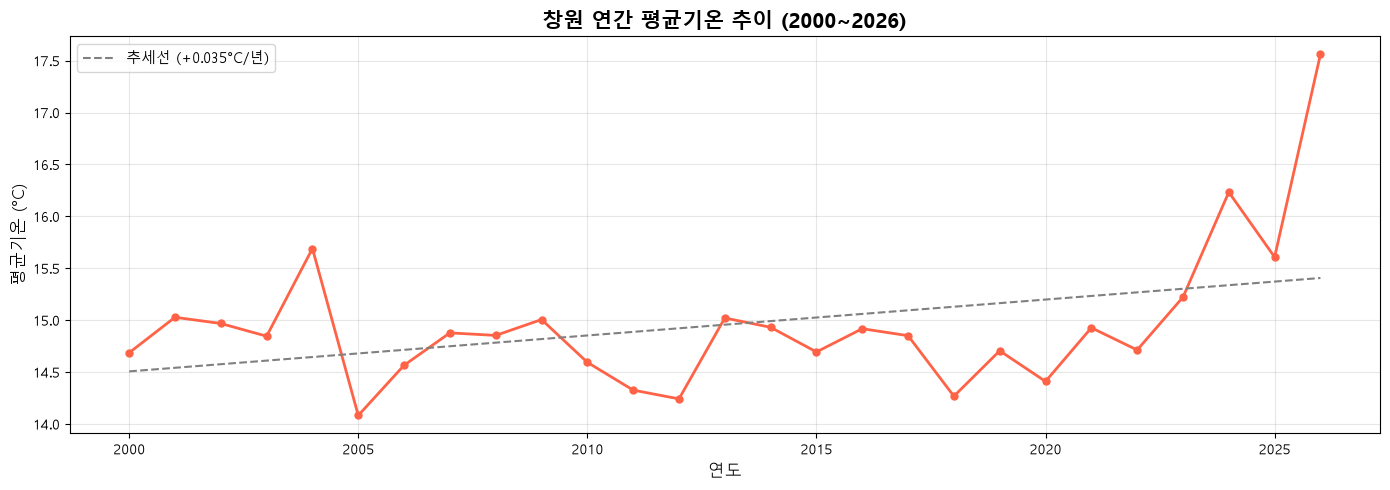

In [6]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 한글 폰트 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 연간 평균기온 계산
yearly_avg = df.groupby('연도')['평균기온(℃)'].mean()

# 그래프 그리기
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(yearly_avg.index, yearly_avg.values,
        marker='o', linewidth=2, color='tomato', markersize=5)

# 추세선 추가
import numpy as np
z = np.polyfit(yearly_avg.index, yearly_avg.values, 1)
p = np.poly1d(z)
ax.plot(yearly_avg.index, p(yearly_avg.index),
        '--', color='gray', linewidth=1.5, label=f'추세선 (+{z[0]:.3f}°C/년)')

ax.set_title('창원 연간 평균기온 추이 (2000~2026)', fontsize=15, fontweight='bold')
ax.set_xlabel('연도', fontsize=12)
ax.set_ylabel('평균기온 (°C)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

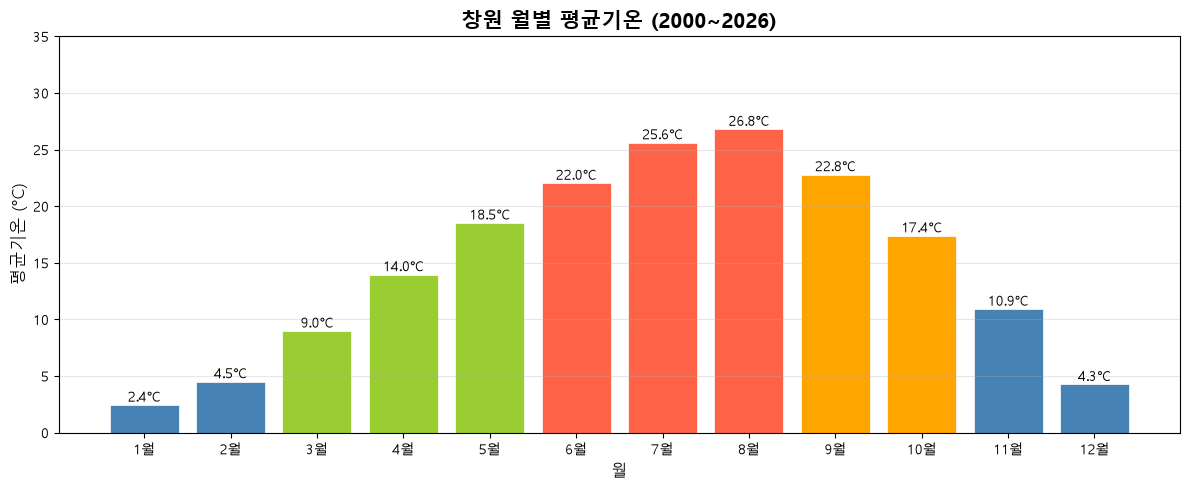

In [7]:
# 월별 평균기온 계산
monthly_avg = df.groupby('월')['평균기온(℃)'].mean()

month_labels = ['1월','2월','3월','4월','5월','6월',
                '7월','8월','9월','10월','11월','12월']

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(month_labels, monthly_avg.values,
              color=['steelblue','steelblue','yellowgreen',
                     'yellowgreen','yellowgreen','tomato',
                     'tomato','tomato','orange',
                     'orange','steelblue','steelblue'],
              edgecolor='white', linewidth=0.5)

# 각 막대 위에 수치 표시
for bar, val in zip(bars, monthly_avg.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{val:.1f}°C', ha='center', fontsize=10)

ax.set_title('창원 월별 평균기온 (2000~2026)', fontsize=15, fontweight='bold')
ax.set_xlabel('월', fontsize=12)
ax.set_ylabel('평균기온 (°C)', fontsize=12)
ax.set_ylim(0, 35)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

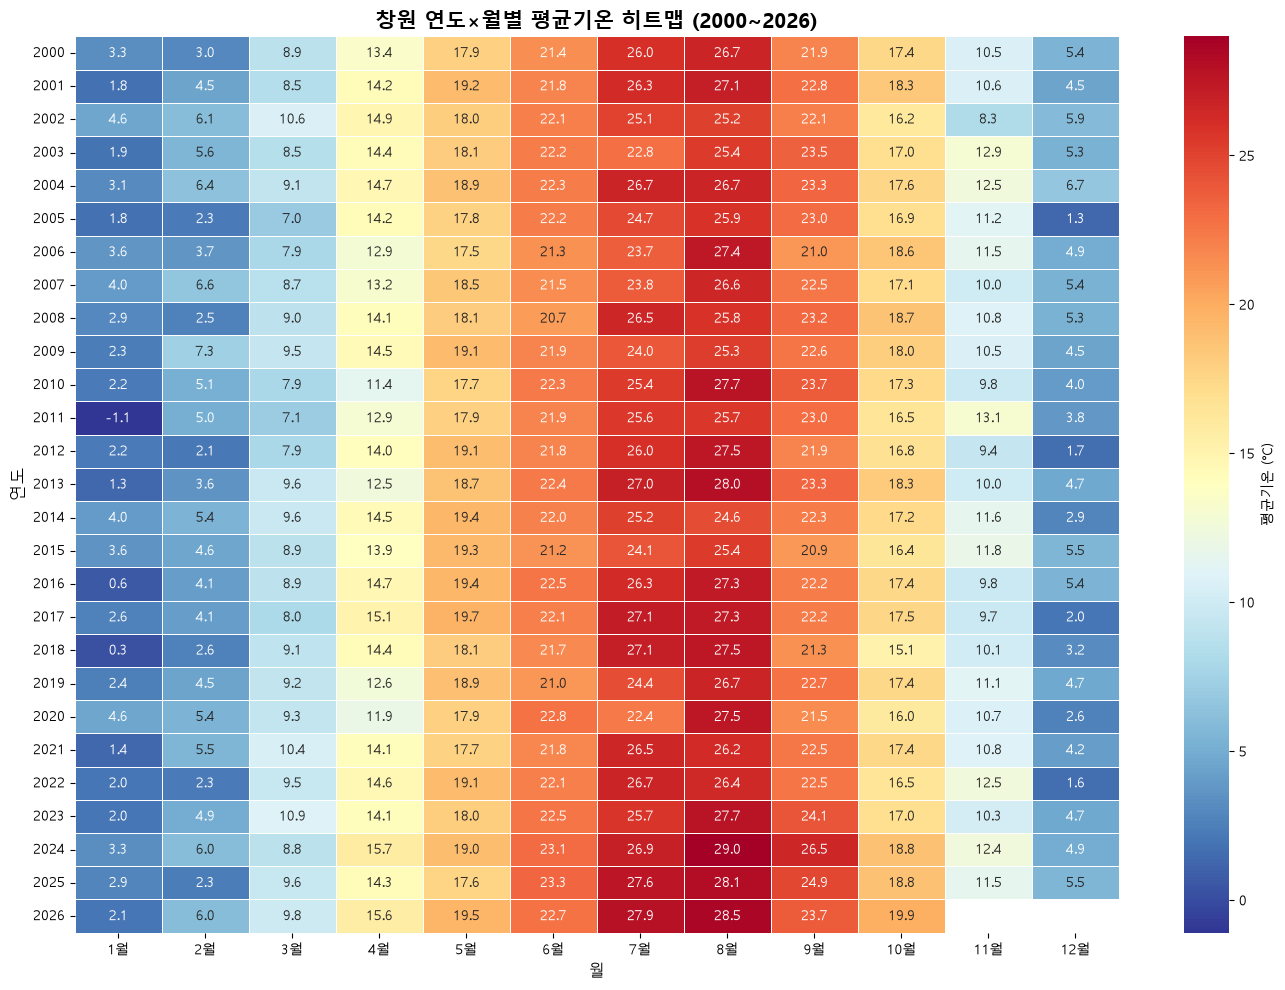

In [8]:
# 연도×월 피벗 테이블 생성
pivot = df.pivot_table(
    values='평균기온(℃)',
    index='연도',
    columns='월',
    aggfunc='mean'
)
pivot.columns = ['1월','2월','3월','4월','5월','6월',
                 '7월','8월','9월','10월','11월','12월']

# 히트맵 그리기
import seaborn as sns

fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(pivot,
            annot=True,        # 수치 표시
            fmt='.1f',         # 소수점 1자리
            cmap='RdYlBu_r',   # 빨강(더움)~파랑(추움)
            linewidths=0.5,
            ax=ax,
            cbar_kws={'label': '평균기온 (°C)'})

ax.set_title('창원 연도×월별 평균기온 히트맵 (2000~2026)',
             fontsize=15, fontweight='bold')
ax.set_xlabel('월', fontsize=12)
ax.set_ylabel('연도', fontsize=12)

plt.tight_layout()
plt.show()

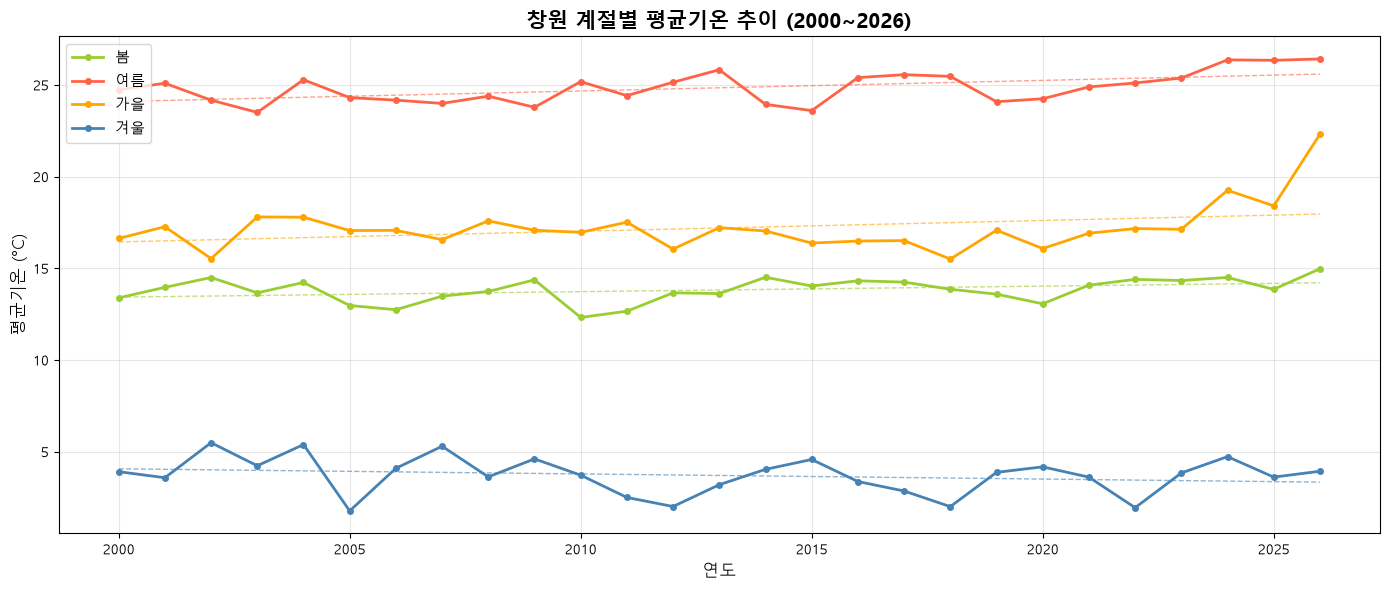

In [9]:
# 계절 분류 함수
def get_season(month):
    if month in [3, 4, 5]:
        return '봄'
    elif month in [6, 7, 8]:
        return '여름'
    elif month in [9, 10, 11]:
        return '가을'
    else:
        return '겨울'

df['계절'] = df['월'].apply(get_season)

# 연도×계절별 평균기온
season_yearly = df.groupby(['연도', '계절'])['평균기온(℃)'].mean().unstack()

# 계절 순서 정렬
season_yearly = season_yearly[['봄', '여름', '가을', '겨울']]

# 그래프
fig, ax = plt.subplots(figsize=(14, 6))

colors = {'봄': 'yellowgreen', '여름': 'tomato',
          '가을': 'orange', '겨울': 'steelblue'}

for season, color in colors.items():
    ax.plot(season_yearly.index,
            season_yearly[season],
            marker='o', linewidth=2,
            color=color, markersize=4,
            label=season)
    # 추세선
    z = np.polyfit(season_yearly.index,
                   season_yearly[season], 1)
    p = np.poly1d(z)
    ax.plot(season_yearly.index, p(season_yearly.index),
            '--', color=color, linewidth=1, alpha=0.6)

ax.set_title('창원 계절별 평균기온 추이 (2000~2026)',
             fontsize=15, fontweight='bold')
ax.set_xlabel('연도', fontsize=12)
ax.set_ylabel('평균기온 (°C)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

2026년 가을(주황선)이 급격히 상승
→ 9·10월 기온이 매우 높았음
→ 히트맵에서 2026년 9월 23.7°C, 10월 19.9°C 확인
→ 이상고온 현상으로 해석 가능

☀️ 여름 : 약 24~26°C 구간
🍂 가을 : 약 16~18°C 구간
🌸 봄   : 약 13~15°C 구간
❄️ 겨울 : 약  3~5°C 구간

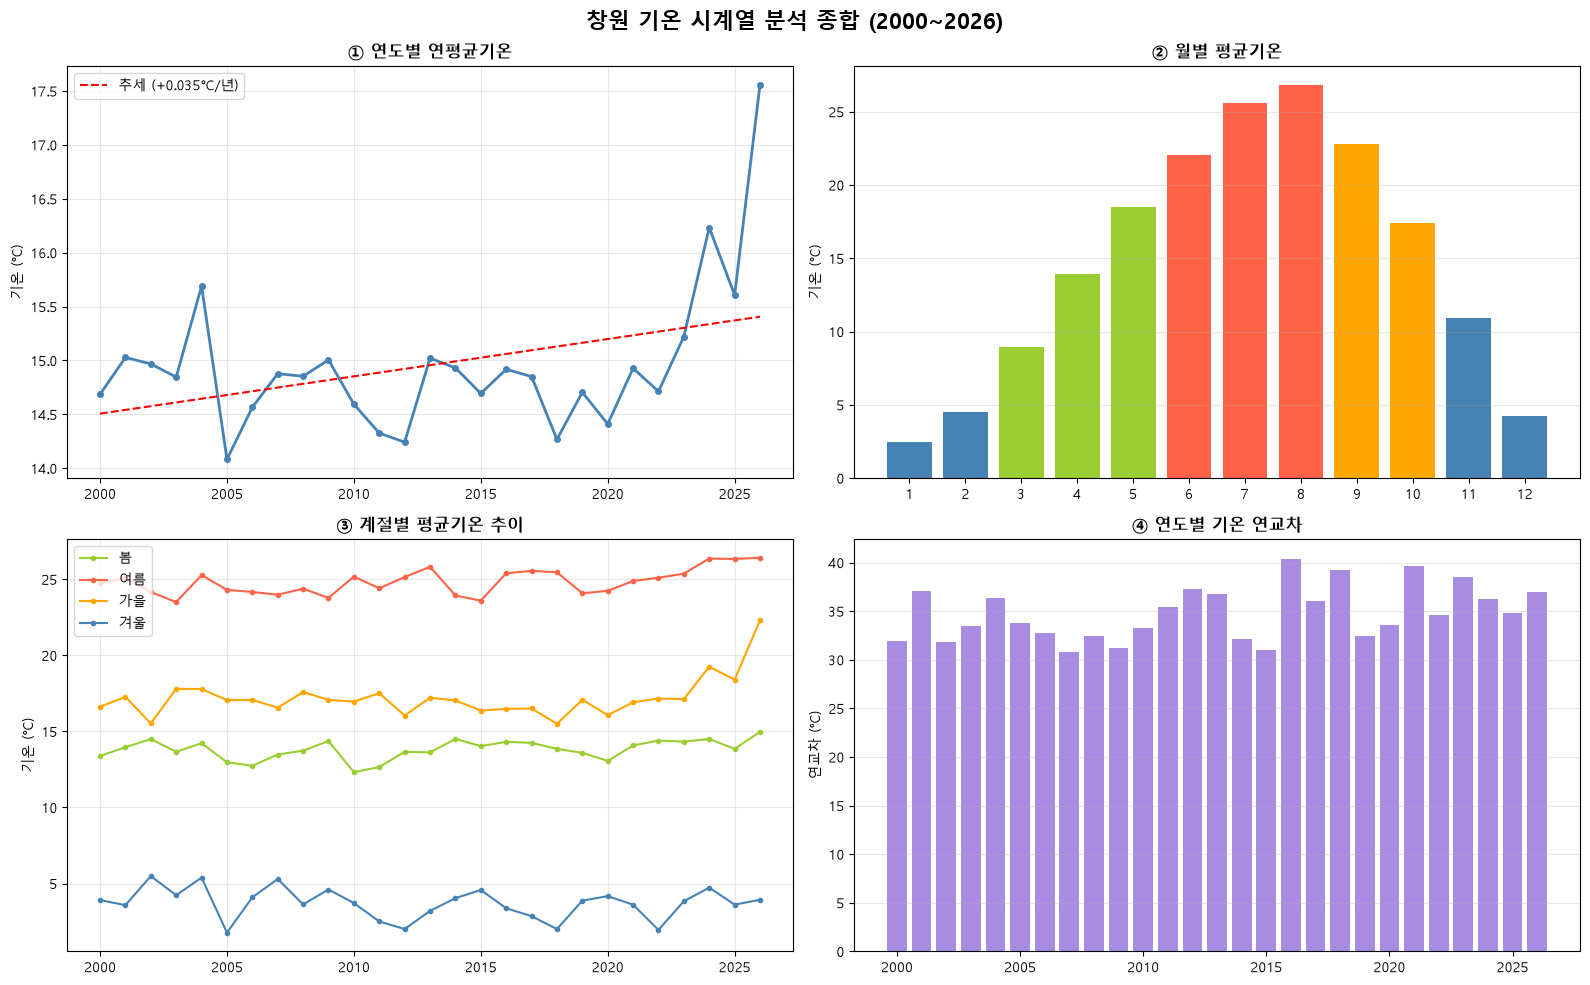

In [10]:
# 4개 그래프를 한 화면에 종합 정리
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('창원 기온 시계열 분석 종합 (2000~2026)',
             fontsize=16, fontweight='bold')

# ① 연도별 연평균기온
yearly_avg = df.groupby('연도')['평균기온(℃)'].mean()
z = np.polyfit(yearly_avg.index, yearly_avg.values, 1)
p = np.poly1d(z)
axes[0,0].plot(yearly_avg.index, yearly_avg.values,
               'o-', color='steelblue', linewidth=2, markersize=4)
axes[0,0].plot(yearly_avg.index, p(yearly_avg.index),
               'r--', linewidth=1.5, label=f'추세 (+{z[0]:.3f}°C/년)')
axes[0,0].set_title('① 연도별 연평균기온', fontweight='bold')
axes[0,0].set_ylabel('기온 (°C)')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# ② 월별 평균기온
monthly_avg = df.groupby('월')['평균기온(℃)'].mean()
month_labels = ['1','2','3','4','5','6','7','8','9','10','11','12']
axes[0,1].bar(month_labels, monthly_avg.values,
              color=['steelblue','steelblue','yellowgreen',
                     'yellowgreen','yellowgreen','tomato',
                     'tomato','tomato','orange',
                     'orange','steelblue','steelblue'])
axes[0,1].set_title('② 월별 평균기온', fontweight='bold')
axes[0,1].set_ylabel('기온 (°C)')
axes[0,1].grid(True, axis='y', alpha=0.3)

# ③ 계절별 추이
colors2 = {'봄':'yellowgreen','여름':'tomato',
           '가을':'orange','겨울':'steelblue'}
for s, c in colors2.items():
    axes[1,0].plot(season_yearly.index,
                   season_yearly[s],
                   marker='o', linewidth=1.5,
                   color=c, markersize=3, label=s)
axes[1,0].set_title('③ 계절별 평균기온 추이', fontweight='bold')
axes[1,0].set_ylabel('기온 (°C)')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# ④ 연교차 (최고-최저 월 기온)
annual_range = df.groupby('연도')['평균기온(℃)'].apply(
    lambda x: x.max() - x.min()
)
axes[1,1].bar(annual_range.index, annual_range.values,
              color='mediumpurple', alpha=0.8)
axes[1,1].set_title('④ 연도별 기온 연교차', fontweight='bold')
axes[1,1].set_ylabel('연교차 (°C)')
axes[1,1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 창원 기온 시계열 분석 보고서

### 1. 분석 개요
- **기간** : 2000년 ~ 2026년 (27년)
- **지점** : 창원 (기상청 155번)
- **분석 항목** : 연평균기온, 월별/계절별 패턴, 연교차

### 2. 주요 발견
1. 연평균기온이 27년간 약 +0.9°C 상승
2. 2020년대 이후 상승 가속화 뚜렷
3. 8월 최고(26.5°C), 1월 최저(3.0°C)
4. 여름/봄 계절에서 온난화 영향 가장 뚜렷
5. 2024년 8월 29.0°C 역대 최고 기록

### 3. 결론
창원은 지난 27년간 뚜렷한 기온 상승 추세를 보이며,
특히 최근 5년간 온난화가 가속되고 있음

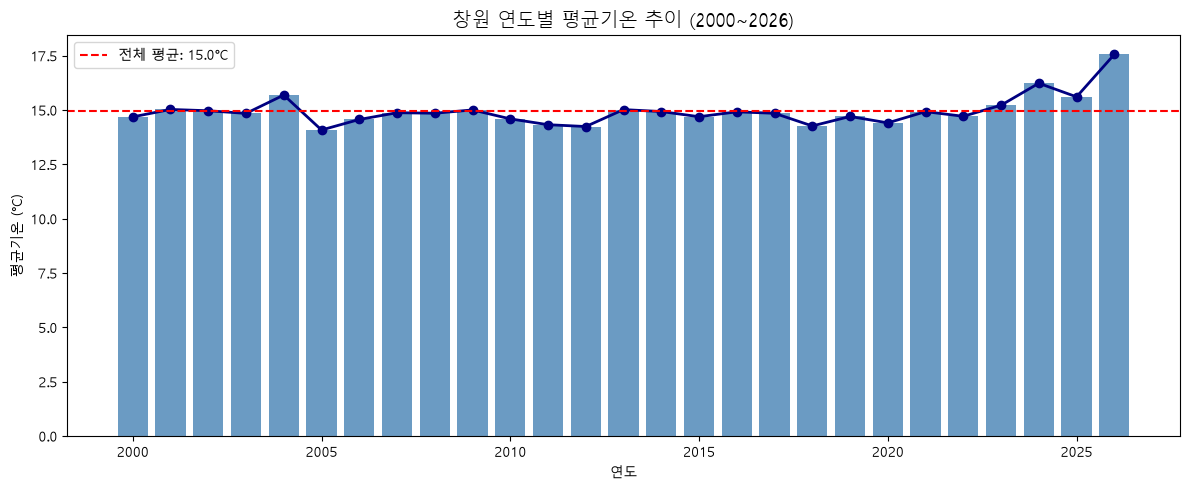

01 저장 완료


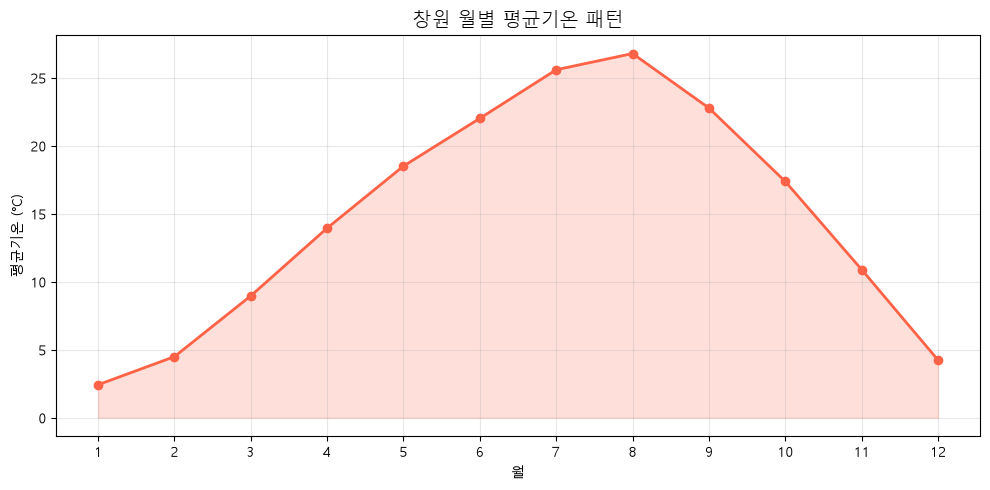

02 저장 완료


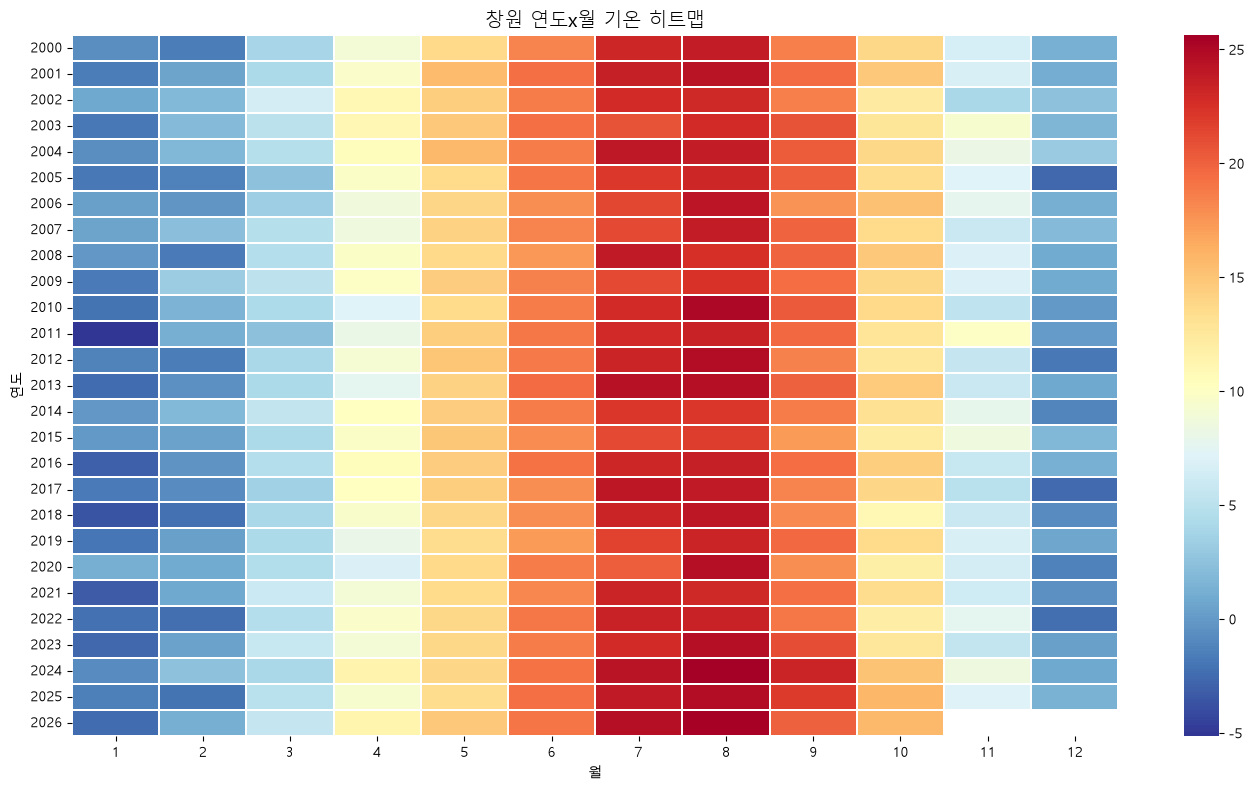

03 저장 완료

 images 폴더에 3개 파일 저장 완료!


In [11]:
import os

# images 폴더 생성
os.makedirs('images', exist_ok=True)

# 그래프 1: 연도별 평균기온 추이
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(yearly_avg.index, yearly_avg.values, color='steelblue', alpha=0.8)
ax.plot(yearly_avg.index, yearly_avg.values, color='navy', marker='o', linewidth=2)
ax.axhline(yearly_avg.mean(), color='red', linestyle='--', label=f'전체 평균: {yearly_avg.mean():.1f}°C')
ax.set_title('창원 연도별 평균기온 추이 (2000~2026)', fontsize=14)
ax.set_xlabel('연도')
ax.set_ylabel('평균기온 (°C)')
ax.legend()
plt.tight_layout()
plt.savefig('images/01_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("01 저장 완료")

# 그래프 2: 월별 평균기온 패턴
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_avg.index, monthly_avg.values, marker='o', color='tomato', linewidth=2)
ax.fill_between(monthly_avg.index, monthly_avg.values, alpha=0.2, color='tomato')
ax.set_title('창원 월별 평균기온 패턴', fontsize=14)
ax.set_xlabel('월')
ax.set_ylabel('평균기온 (°C)')
ax.set_xticks(range(1, 13))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/02_monthly_pattern.png', dpi=150, bbox_inches='tight')
plt.show()
print("02 저장 완료")

# 그래프 3: 히트맵
import seaborn as sns
heatmap_df = df.copy()
date_col = heatmap_df.columns[0]
temp_col = heatmap_df.columns[2]

heatmap_df["year"] = pd.to_datetime(
    heatmap_df[date_col]
).dt.year

heatmap_df["month"] = pd.to_datetime(
    heatmap_df[date_col]
).dt.month

pivot = heatmap_df.pivot_table(
    values=temp_col,
    index="year",
    columns="month",
    aggfunc="mean"
)
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot, cmap='RdYlBu_r', annot=False, linewidths=0.3, ax=ax)
ax.set_title('창원 연도x월 기온 히트맵', fontsize=14)
ax.set_xlabel('월')
ax.set_ylabel('연도')
plt.tight_layout()
plt.savefig('images/03_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("03 저장 완료")

print("\n images 폴더에 3개 파일 저장 완료!")

In [12]:
%whos

Variable        Type            Data/Info
-----------------------------------------
annual_range    Series          Shape: (27,)
ax              Axes            Axes(0.0550416,0.0736839;0.747395x0.875899)
axes            ndarray         2x2: 4 elems, type `object`, 32 bytes
bar             Rectangle       Rectangle(xy=(10.6, 0), w<...> height=4.25323, angle=0)
bars            BarContainer    <BarContainer object of 12 artists>
c               str             steelblue
color           str             steelblue
colors          dict            n=4
colors2         dict            n=4
date_col        str             날짜
df              DataFrame       Shape: (9788, 7)
fig             Figure          Figure(1400x800)
fm              module          <module 'matplotlib.font_<...>lotlib\\font_manager.py'>
get_season      function        <function get_season at 0x00000207F2680F60>
heatmap_df      DataFrame       Shape: (9788, 9)
month_labels    list            n=12
monthly_avg     Series        

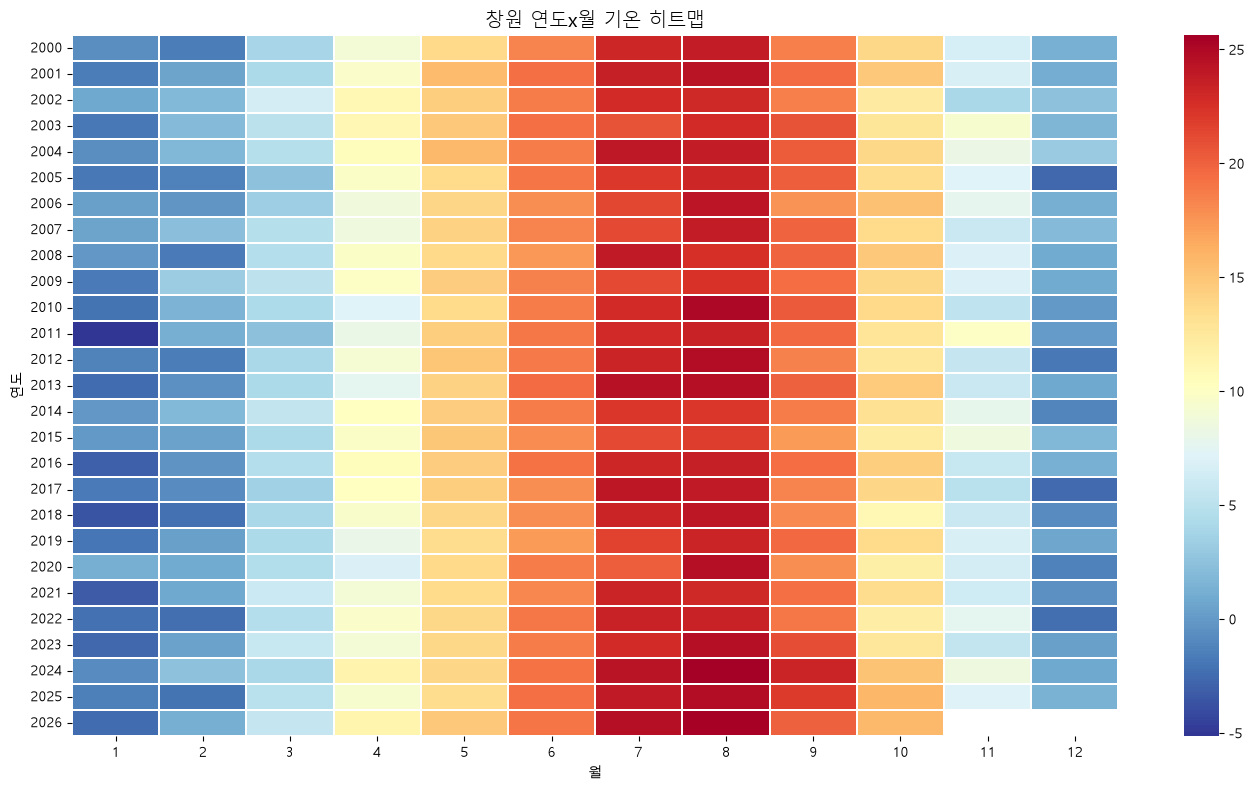

✅ 히트맵 저장 완료!


In [13]:
import os
import seaborn as sns

os.makedirs('images', exist_ok=True)

# 히트맵 (이미 만들어진 pivot 사용!)
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot, cmap='RdYlBu_r', annot=False, linewidths=0.3, ax=ax)
ax.set_title('창원 연도x월 기온 히트맵', fontsize=14)
ax.set_xlabel('월')
ax.set_ylabel('연도')
plt.tight_layout()
plt.savefig('images/03_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 히트맵 저장 완료!")

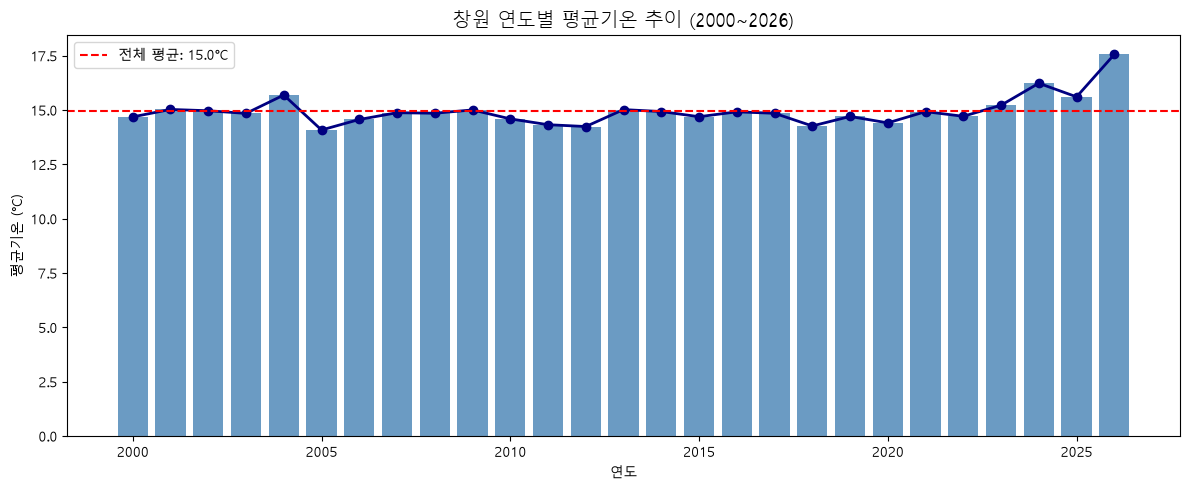

✅ 01 연도별 추이 저장 완료!


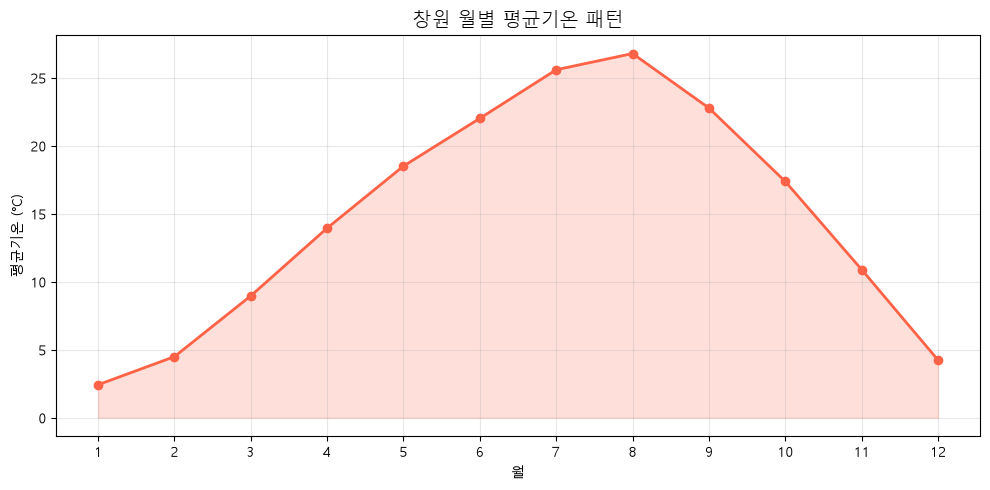

✅ 02 월별 패턴 저장 완료!

🎊 총 2개 추가 저장 완료!


In [14]:
import os
os.makedirs('images', exist_ok=True)

# 그래프 1: 연도별 평균기온 추이
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(yearly_avg.index, yearly_avg.values, color='steelblue', alpha=0.8)
ax.plot(yearly_avg.index, yearly_avg.values, color='navy', marker='o', linewidth=2)
ax.axhline(yearly_avg.mean(), color='red', linestyle='--', 
           label=f'전체 평균: {yearly_avg.mean():.1f}°C')
ax.set_title('창원 연도별 평균기온 추이 (2000~2026)', fontsize=14)
ax.set_xlabel('연도')
ax.set_ylabel('평균기온 (°C)')
ax.legend()
plt.tight_layout()
plt.savefig('images/01_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 01 연도별 추이 저장 완료!")

# 그래프 2: 월별 평균기온 패턴
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_avg.index, monthly_avg.values, 
        marker='o', color='tomato', linewidth=2)
ax.fill_between(monthly_avg.index, monthly_avg.values, alpha=0.2, color='tomato')
ax.set_title('창원 월별 평균기온 패턴', fontsize=14)
ax.set_xlabel('월')
ax.set_ylabel('평균기온 (°C)')
ax.set_xticks(range(1, 13))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/02_monthly_pattern.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 02 월별 패턴 저장 완료!")

print("\n🎊 총 2개 추가 저장 완료!")

In [15]:
dec_data = df[df['날짜'].dt.month == 12].groupby(
    df['날짜'].dt.year
)[df.columns[2]].mean()

print("=== 12월 연도별 평균기온 ===")
print(dec_data)
print(f"\n2000~2004년 평균: {dec_data[2000:2005].mean():.1f}°C")
print(f"2020~2024년 평균: {dec_data[2020:2025].mean():.1f}°C")

=== 12월 연도별 평균기온 ===
날짜
2000    1.267742
2001    0.983871
2002    2.535484
2003    1.596774
2004    3.093548
2005   -2.735484
2006    1.151613
2007    2.006452
2008    0.935484
2009    0.951613
2010   -0.096774
2011    0.067742
2012   -1.854839
2013    0.770968
2014   -1.096774
2015    1.741935
2016    1.235484
2017   -2.574194
2018   -0.703226
2019    0.658065
2020   -1.345161
2021   -0.483871
2022   -2.364516
2023    0.348387
2024    0.829032
2025    1.374194
Name: 최저기온(℃), dtype: float64

2000~2004년 평균: nan°C
2020~2024년 평균: nan°C


In [16]:
# 컬럼명 확인
print(df.columns.tolist())
print(df.head(2))

['날짜', '평균기온(℃)', '최저기온(℃)', '최고기온(℃)', '연도', '월', '계절']
          날짜  평균기온(℃)  최저기온(℃)  최고기온(℃)    연도  월  계절
0 2000-01-01      7.5      1.8     11.7  2000  1  겨울
1 2000-01-02      8.8      5.2     12.6  2000  1  겨울


In [17]:
dec_data = df[df['날짜'].dt.month == 12].groupby(
    df['날짜'].dt.year
)['평균기온(℃)'].mean()

print("=== 12월 연도별 평균기온 ===")
print(dec_data)
print(f"\n2000~2004년 평균: {dec_data[2000:2005].mean():.1f}°C")
print(f"2020~2024년 평균: {dec_data[2020:2025].mean():.1f}°C")

=== 12월 연도별 평균기온 ===
날짜
2000    5.383871
2001    4.464516
2002    5.867742
2003    5.319355
2004    6.738710
2005    1.338710
2006    4.896774
2007    5.354839
2008    5.322581
2009    4.461290
2010    3.961290
2011    3.832258
2012    1.661290
2013    4.693548
2014    2.893548
2015    5.487097
2016    5.432258
2017    2.003226
2018    3.187097
2019    4.722581
2020    2.641935
2021    4.158065
2022    1.616129
2023    4.693548
2024    4.922581
2025    5.529032
Name: 평균기온(℃), dtype: float64

2000~2004년 평균: nan°C
2020~2024년 평균: nan°C


In [18]:
# isin() 방식으로 정확하게 선택
early = dec_data[dec_data.index.isin(range(2000, 2005))].mean()
recent = dec_data[dec_data.index.isin(range(2020, 2025))].mean()

print("=== 12월 연도별 평균기온 ===")
print(f"2000~2004년 12월 평균: {early:.1f}°C")
print(f"2020~2024년 12월 평균: {recent:.1f}°C")
print(f"차이: {recent - early:+.1f}°C")

=== 12월 연도별 평균기온 ===
2000~2004년 12월 평균: 5.6°C
2020~2024년 12월 평균: 3.6°C
차이: -1.9°C


MA30 VALID: 9759
MA365 VALID: 9424


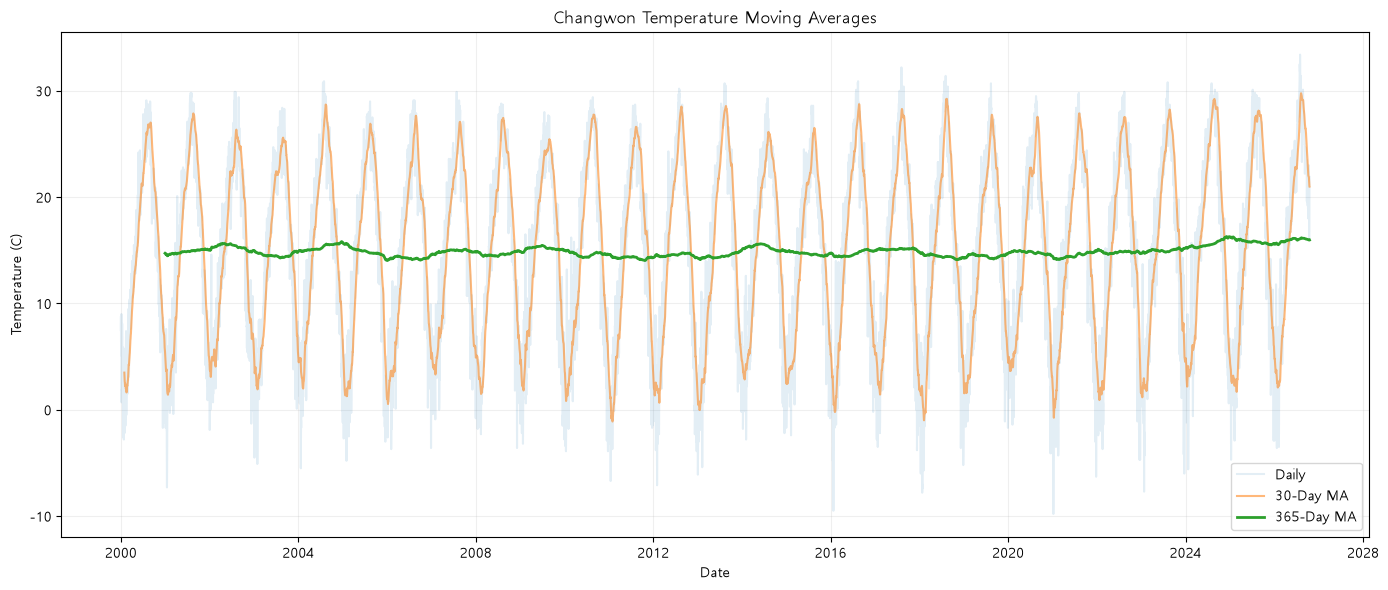

MOVING AVERAGE COMPLETE


In [19]:
# STEP 3: MOVING AVERAGE ANALYSIS
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data = pd.read_csv(
    "data/changwon_temp.csv",
    encoding="cp949",
    skiprows=7
)

date_col = data.columns[0]
temp_col = data.columns[2]

data[date_col] = pd.to_datetime(
    data[date_col].astype(str).str.strip()
)

data = data.sort_values(date_col)
data = data.set_index(date_col)

data["MA30"] = data[temp_col].rolling(
    30, min_periods=30
).mean()

data["MA365"] = data[temp_col].rolling(
    365, min_periods=365
).mean()

print("MA30 VALID:", data["MA30"].count())
print("MA365 VALID:", data["MA365"].count())

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(data.index, data[temp_col],
        alpha=0.12, label="Daily")
ax.plot(data.index, data["MA30"],
        alpha=0.55, label="30-Day MA")
ax.plot(data.index, data["MA365"],
        linewidth=2, label="365-Day MA")

ax.set_title("Changwon Temperature Moving Averages")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (C)")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
Path("images").mkdir(exist_ok=True)
fig.savefig("images/04_moving_average.png", dpi=150)
plt.show()
plt.close(fig)

print("MOVING AVERAGE COMPLETE")


MONTHLY OBSERVATIONS: 321
INCOMPLETE MONTHS: 0
MISSING MONTHLY VALUES: 0


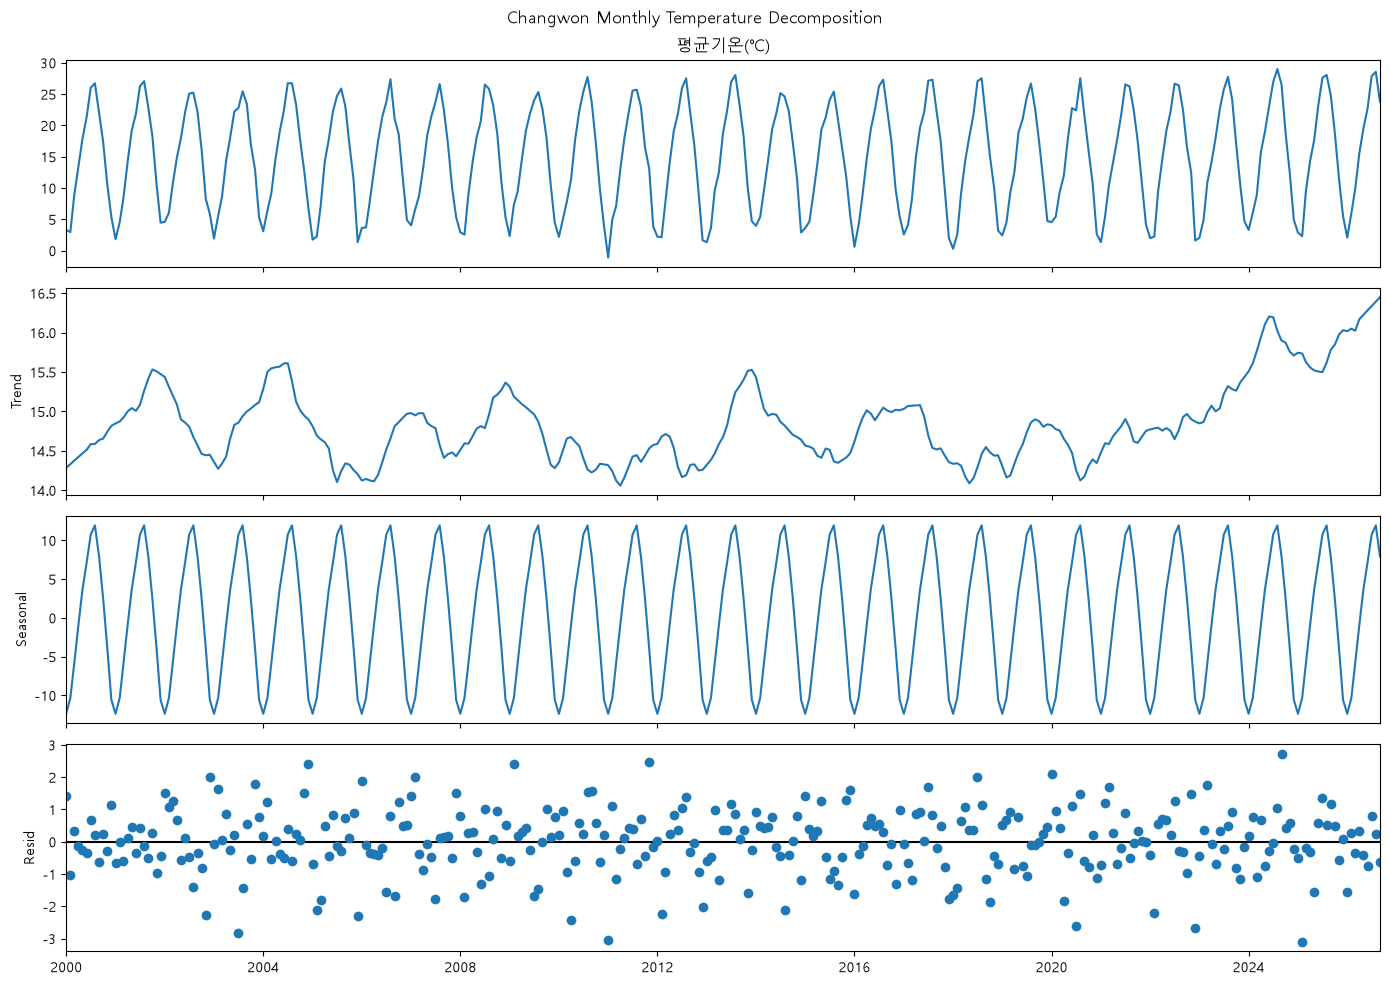

DECOMPOSITION COMPLETE


In [20]:
# STEP 4: SEASONAL DECOMPOSITION
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose

df4 = pd.read_csv(
    "data/changwon_temp.csv",
    encoding="cp949",
    skiprows=7
)

date_col = df4.columns[0]
temp_col = df4.columns[2]

df4[date_col] = pd.to_datetime(
    df4[date_col].astype(str).str.strip()
)

df4 = df4.sort_values(date_col).set_index(date_col)

monthly = df4[temp_col].resample("MS").mean()
monthly = monthly.loc[:"2026-09-01"]

counts = df4[temp_col].resample("MS").count()
incomplete = counts.reindex(monthly.index) != monthly.index.days_in_month

print("MONTHLY OBSERVATIONS:", len(monthly))
print("INCOMPLETE MONTHS:", int(incomplete.sum()))
print("MISSING MONTHLY VALUES:", int(monthly.isna().sum()))

if incomplete.any() or monthly.isna().any():
    raise ValueError("Incomplete monthly data found")

result = seasonal_decompose(
    monthly,
    model="additive",
    period=12,
    extrapolate_trend="period"
)

fig = result.plot()
fig.set_size_inches(14, 10)
fig.suptitle("Changwon Monthly Temperature Decomposition")
fig.tight_layout()

Path("images").mkdir(exist_ok=True)
fig.savefig(
    "images/05_seasonal_decomposition.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("DECOMPOSITION COMPLETE")


2000-2012: -0.443
2013-2025: 0.649
2000-2025: 0.147
Monthly points: 312
Yearly points: 26
Monthly STD: 8.323
Yearly STD: 0.467


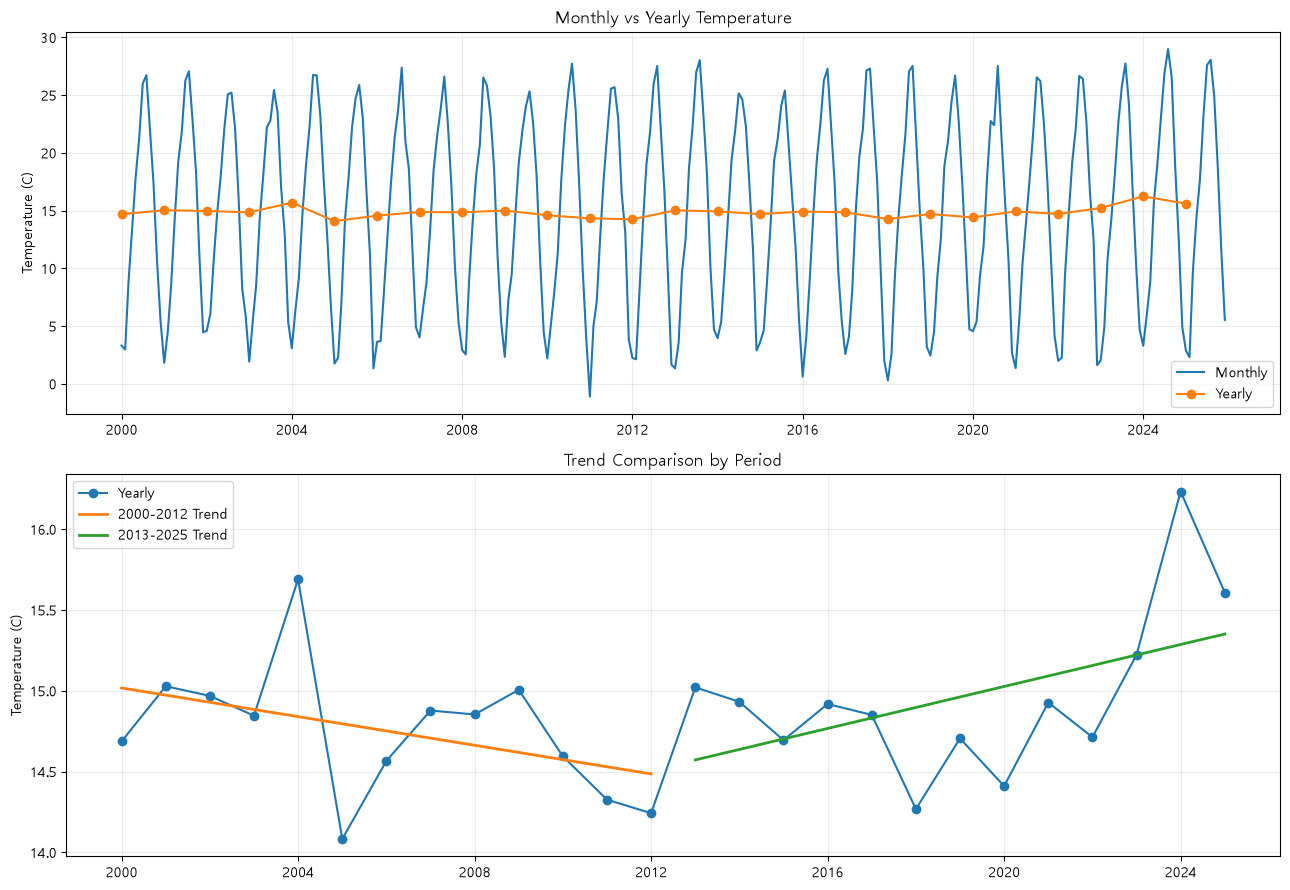

STEP5 NOTEBOOK COMPLETE


In [21]:
# STEP 5: PERIOD AND AGGREGATION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df5 = pd.read_csv(
    "data/changwon_temp.csv",
    encoding="cp949",
    skiprows=7
)

date_col = df5.columns[0]
temp_col = df5.columns[2]

df5[date_col] = pd.to_datetime(
    df5[date_col].astype(str).str.strip()
)

df5 = df5.sort_values(date_col).set_index(date_col)
df5 = df5.loc["2000-01-01":"2025-12-31"]

monthly5 = df5[temp_col].resample("MS").mean()
yearly5 = df5[temp_col].resample("YS").mean()

first5 = yearly5.loc["2000":"2012"]
second5 = yearly5.loc["2013":"2025"]

def slope_decade(series):
    x = series.index.year.to_numpy(dtype=float)
    y = series.to_numpy(dtype=float)
    return np.polyfit(x, y, 1)[0] * 10

print("2000-2012:", round(slope_decade(first5), 3))
print("2013-2025:", round(slope_decade(second5), 3))
print("2000-2025:", round(slope_decade(yearly5), 3))
print("Monthly points:", len(monthly5))
print("Yearly points:", len(yearly5))
print("Monthly STD:", round(monthly5.std(), 3))
print("Yearly STD:", round(yearly5.std(), 3))

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

axes[0].plot(monthly5.index, monthly5, label="Monthly")
axes[0].plot(yearly5.index, yearly5, marker="o", label="Yearly")
axes[0].set_title("Monthly vs Yearly Temperature")
axes[0].set_ylabel("Temperature (C)")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(yearly5.index, yearly5, marker="o", label="Yearly")

for subset, label in [(first5, "2000-2012"),
                      (second5, "2013-2025")]:
    x = subset.index.year.to_numpy(dtype=float)
    y = subset.to_numpy(dtype=float)
    m, b = np.polyfit(x, y, 1)
    axes[1].plot(
        subset.index, m*x+b, linewidth=2,
        label=label+" Trend"
    )

axes[1].set_title("Trend Comparison by Period")
axes[1].set_ylabel("Temperature (C)")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
Path("images").mkdir(exist_ok=True)
fig.savefig("images/06_period_aggregation.png", dpi=150)
plt.show()
plt.close(fig)

print("STEP5 NOTEBOOK COMPLETE")
